# **Install, Import and Environment Setup**

In [ ]:
!pip install -q kaggle scikit-learn seaborn opencv-python-headless imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 7.8 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 2 — IMPORTS & ENVIRONMENT
# ============================================================

import os
import shutil
import time
import json
import random
import hashlib
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import cv2
from PIL import Image
import imagehash

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# Environment information
# ------------------------------------------------------------

print("=" * 70)
print("ENVIRONMENT CHECK")
print("=" * 70)

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("GPU devices:", gpus)
print("Number of GPUs:", len(gpus))

if gpus:
    print("\nGPU AVAILABLE ")
    for gpu in gpus:
        print("  ", gpu)
else:
    print("\nNO GPU DETECTED ")
    print("Go to Runtime → Change runtime type → T4 GPU")

print("=" * 70)

ENVIRONMENT CHECK
TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Number of GPUs: 1

GPU AVAILABLE 
   PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


# **Kaggle Setup**

In [ ]:
# ============================================================
# CELL 3 — KAGGLE API AUTHENTICATION
# ============================================================

from google.colab import userdata

print("Attempting to load Kaggle credentials from Colab Secrets...")

try:
    KAGGLE_API_TOKEN = userdata.get("KAGGLE_API_TOKEN")
    print("Kaggle API token found in Colab Secrets ")
except Exception:
    KAGGLE_API_TOKEN = None
    print("No KAGGLE_API_TOKEN found in Colab Secrets.")

Attempting to load Kaggle credentials from Colab Secrets...
Kaggle API token found in Colab Secrets 


In [ ]:
# ============================================================
# CELL 4 — CONFIGURE KAGGLE
# ============================================================

if KAGGLE_API_TOKEN is not None:

    os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

    print("Kaggle API token configured ")

else:

    print(
        "Kaggle token not configured.\n"
        "Add KAGGLE_API_TOKEN under Colab Secrets and rerun this cell."
    )

Kaggle API token configured 


# **Download Dataset**

In [ ]:
# ============================================================
# CELL 5 — DOWNLOAD DATASET
# ============================================================

DATA_ROOT = "/content/data"

os.makedirs(DATA_ROOT, exist_ok=True)

!kaggle datasets download \
    -d rashikrahmanpritom/plant-disease-recognition-dataset \
    -p /content/data \
    --unzip

print("\nDataset downloaded.")

Dataset URL: https://www.kaggle.com/datasets/rashikrahmanpritom/plant-disease-recognition-dataset
License(s): CC0-1.0
100% 1.25G/1.25G [00:16<00:00, 81.0MB/s]


Dataset downloaded.


# **Inspect Dataset Structure**

In [ ]:
# ============================================================
# CELL 6 — DATASET STRUCTURE
# ============================================================

print("=" * 70)
print("DATASET DIRECTORY STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(DATA_ROOT):

    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level <= 3:

        indent = "    " * level

        print(
            indent +
            os.path.basename(root) +
            "/"
        )

DATASET DIRECTORY STRUCTURE
data/
    Validation/
        Validation/
            Rust/
            Powdery/
            Healthy/
    Test/
        Test/
            Rust/
            Powdery/
            Healthy/
    Train/
        Train/
            Rust/
            Powdery/
            Healthy/


# **Find the actual split directories**

In [ ]:
# ============================================================
# CELL 7 — LOCATE TRAIN / VALIDATION / TEST DIRECTORIES
# ============================================================

def find_split_dir(root, split_name):

    candidates = []

    for current_root, dirs, files in os.walk(root):

        if os.path.basename(current_root).lower() == split_name.lower():

            # Check that this directory contains subdirectories
            subdirs = [
                d for d in os.listdir(current_root)
                if os.path.isdir(
                    os.path.join(current_root, d)
                )
            ]

            if subdirs:
                candidates.append(current_root)

    if not candidates:
        return None

    # Prefer the deepest matching directory
    return max(candidates, key=lambda x: x.count(os.sep))


TRAIN_DIR = find_split_dir(DATA_ROOT, "Train")
VAL_DIR   = find_split_dir(DATA_ROOT, "Validation")
TEST_DIR  = find_split_dir(DATA_ROOT, "Test")


print("=" * 70)
print("DATASET DIRECTORIES")
print("=" * 70)

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

DATASET DIRECTORIES
Train: /content/data/Train/Train
Validation: /content/data/Validation/Validation
Test: /content/data/Test/Test


# **Discover classes**

In [ ]:
# ============================================================
# CELL 8 — DISCOVER CLASSES
# ============================================================

CLASS_NAMES = sorted([
    d for d in os.listdir(TRAIN_DIR)
    if os.path.isdir(
        os.path.join(TRAIN_DIR, d)
    )
])

NUM_CLASSES = len(CLASS_NAMES)

print("=" * 70)
print("CLASS INFORMATION")
print("=" * 70)

print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)

CLASS INFORMATION
Number of classes: 3
Classes: ['Healthy', 'Powdery', 'Rust']


# **Dataset statistics**

In [ ]:
# ============================================================
# CELL 9 — DATASET STATISTICS
# ============================================================

VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png"
)


def count_images(split_dir):

    counts = {}

    for cls in CLASS_NAMES:

        cls_dir = os.path.join(
            split_dir,
            cls
        )

        counts[cls] = len([
            f for f in os.listdir(cls_dir)
            if f.lower().endswith(VALID_EXTENSIONS)
        ])

    return counts


train_counts = count_images(TRAIN_DIR)
val_counts   = count_images(VAL_DIR)
test_counts  = count_images(TEST_DIR)


summary = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": [train_counts[c] for c in CLASS_NAMES],
    "validation": [val_counts[c] for c in CLASS_NAMES],
    "test": [test_counts[c] for c in CLASS_NAMES]
})


summary["total"] = (
    summary["train"] +
    summary["validation"] +
    summary["test"]
)


print("=" * 70)
print("DATASET SUMMARY")
print("=" * 70)

display(summary)

print("\nTotal images:",
      summary["total"].sum())

print("Training images:",
      summary["train"].sum())

print("Validation images:",
      summary["validation"].sum())

print("Test images:",
      summary["test"].sum())

DATASET SUMMARY


,class,train,validation,test,total
0,Healthy,458,20,50,528
1,Powdery,430,20,50,500
2,Rust,434,20,50,504



Total images: 1532
Training images: 1322
Validation images: 60
Test images: 150


# **Class distribution**

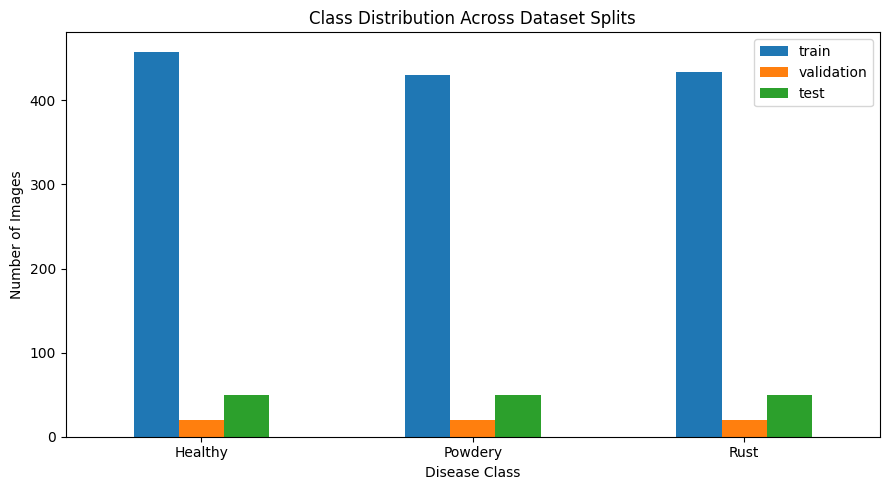

In [ ]:
# ============================================================
# CELL 10 — CLASS DISTRIBUTION
# ============================================================

plot_df = summary.set_index("class")[
    ["train", "validation", "test"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "/content/class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# **Image quality check**

In [ ]:
# ============================================================
# CELL 11 — IMAGE QUALITY CHECK
# ============================================================

def check_image_quality(split_dir, split_name):

    total = 0
    corrupted = []

    for cls in CLASS_NAMES:

        cls_dir = os.path.join(
            split_dir,
            cls
        )

        for fname in os.listdir(cls_dir):

            if not fname.lower().endswith(
                VALID_EXTENSIONS
            ):
                continue

            total += 1

            path = os.path.join(
                cls_dir,
                fname
            )

            try:
                with Image.open(path) as img:
                    img.verify()

            except Exception as e:
                corrupted.append(
                    (path, str(e))
                )

    print(f"\n--- {split_name} ---")
    print("Images checked:", total)
    print("Corrupted images:", len(corrupted))

    return corrupted


train_corrupt = check_image_quality(
    TRAIN_DIR,
    "Train"
)

val_corrupt = check_image_quality(
    VAL_DIR,
    "Validation"
)

test_corrupt = check_image_quality(
    TEST_DIR,
    "Test"
)


--- Train ---
Images checked: 1322
Corrupted images: 0

--- Validation ---
Images checked: 60
Corrupted images: 0

--- Test ---
Images checked: 150
Corrupted images: 0


# **Visualize the dataset**

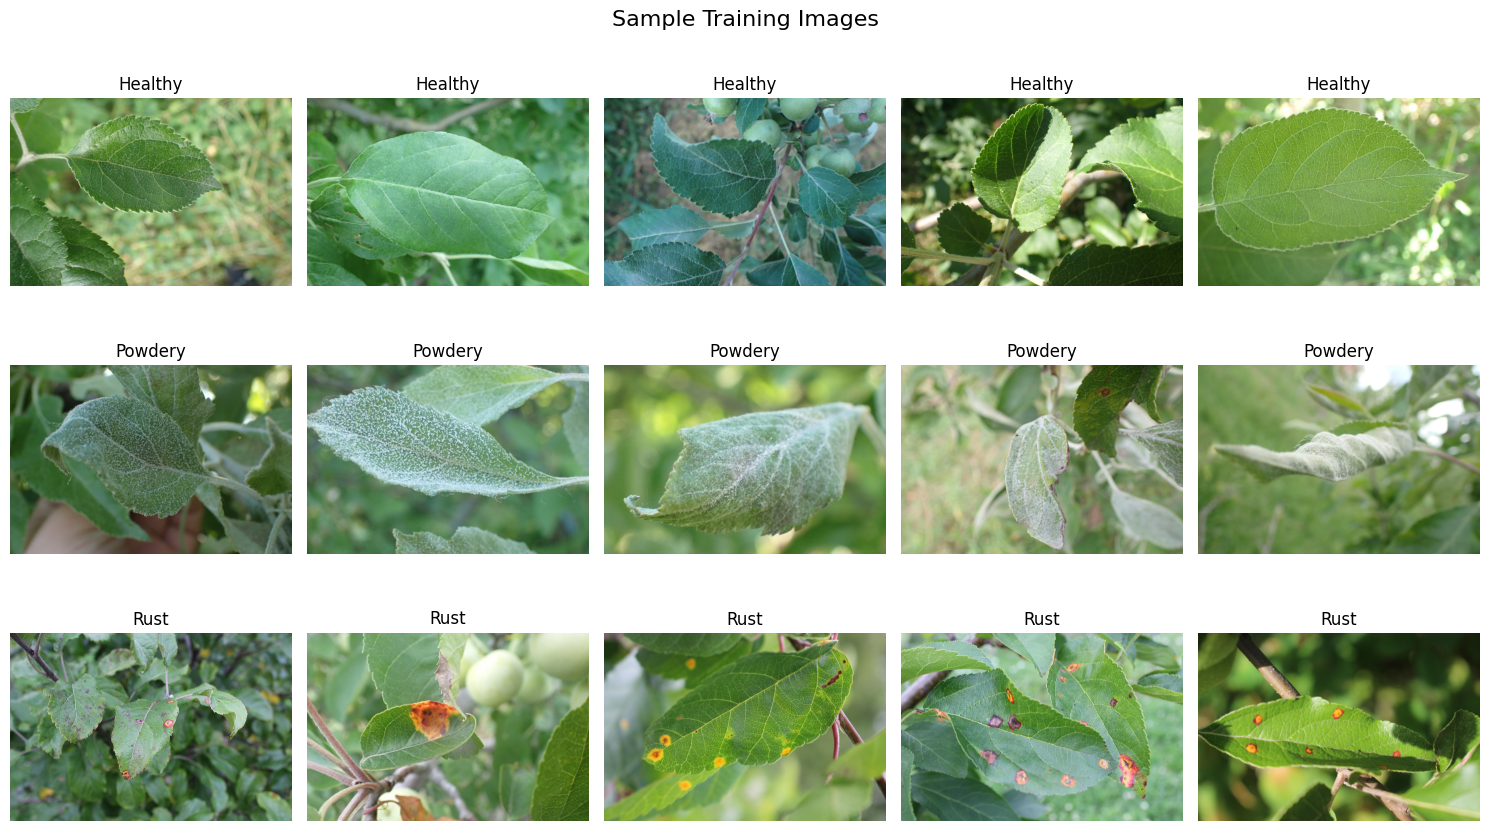

In [ ]:
# ============================================================
# CELL 12 — SAMPLE IMAGES
# ============================================================

fig, axes = plt.subplots(
    NUM_CLASSES,
    5,
    figsize=(15, 9)
)

for row, cls in enumerate(CLASS_NAMES):

    cls_dir = os.path.join(
        TRAIN_DIR,
        cls
    )

    files = sorted([
        f for f in os.listdir(cls_dir)
        if f.lower().endswith(VALID_EXTENSIONS)
    ])

    selected = random.sample(
        files,
        min(5, len(files))
    )

    for col, fname in enumerate(selected):

        path = os.path.join(
            cls_dir,
            fname
        )

        img = Image.open(path)

        axes[row, col].imshow(img)
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")


plt.suptitle(
    "Sample Training Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

# **Create clean datasets**

In [ ]:
# ============================================================
# CELL 13 — CREATE TRAIN / VALIDATION / TEST DATASETS
# ============================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("=" * 70)
print("CREATING DATASETS")
print("=" * 70)

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nDatasets created successfully.")

CREATING DATASETS
Found 1322 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 150 files belonging to 3 classes.

Datasets created successfully.


# **Optimize the input pipeline**

In [ ]:
# ============================================================
# CELL 14 — OPTIMIZE DATA PIPELINE
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Input pipeline optimized.")

Input pipeline optimized.


# **Verify labels BEFORE training**

In [ ]:
# ============================================================
# CELL 15 — VERIFY LABEL DISTRIBUTION
# ============================================================

label_counts = np.zeros(NUM_CLASSES, dtype=int)

for images, labels in train_ds:

    batch_labels = np.argmax(
        labels.numpy(),
        axis=1
    )

    for label in batch_labels:
        label_counts[label] += 1


print("=" * 70)
print("TRAINING LABEL DISTRIBUTION")
print("=" * 70)

for i, cls in enumerate(CLASS_NAMES):
    print(f"{i} - {cls}: {label_counts[i]}")

print("\nExpected:")
for i, cls in enumerate(CLASS_NAMES):
    print(f"{i} - {cls}: {train_counts[cls]}")

TRAINING LABEL DISTRIBUTION
0 - Healthy: 458
1 - Powdery: 430
2 - Rust: 434

Expected:
0 - Healthy: 458
1 - Powdery: 430
2 - Rust: 434


# **Create augmentation**

In [ ]:
# ============================================================
# CELL 16 — DATA AUGMENTATION
# ============================================================

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            "horizontal"
        ),

        layers.RandomRotation(
            0.08
        ),

        layers.RandomZoom(
            0.15
        ),

        layers.RandomTranslation(
            height_factor=0.10,
            width_factor=0.10
        ),

        layers.RandomContrast(
            0.10
        ),
    ],
    name="data_augmentation"
)

print("Augmentation pipeline created.")

Augmentation pipeline created.


# **Build the Custom CNN**

In [ ]:
# ============================================================
# CELL 17 — CUSTOM CNN
# ============================================================

def build_custom_cnn(
    input_shape=(224, 224, 3),
    num_classes=3
):

    inputs = layers.Input(
        shape=input_shape
    )

    # Augmentation
    x = data_augmentation(inputs)

    # Normalize pixels to [0, 1]
    x = layers.Rescaling(
        1.0 / 255.0
    )(x)

    # --------------------------------------------------------
    # Block 1
    # --------------------------------------------------------

    x = layers.Conv2D(
        32,
        3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D()(x)

    # --------------------------------------------------------
    # Block 2
    # --------------------------------------------------------

    x = layers.Conv2D(
        64,
        3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D()(x)

    # --------------------------------------------------------
    # Block 3
    # --------------------------------------------------------

    x = layers.Conv2D(
        128,
        3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D()(x)

    # --------------------------------------------------------
    # Block 4
    # --------------------------------------------------------

    x = layers.Conv2D(
        256,
        3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling2D()(x)

    # --------------------------------------------------------
    # Classifier
    # --------------------------------------------------------

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(
        0.4
    )(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return Model(
        inputs,
        outputs,
        name="Custom_CNN"
    )


custom_cnn = build_custom_cnn(
    input_shape=(*IMG_SIZE, 3),
    num_classes=NUM_CLASSES
)

custom_cnn.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,699 (1.61 MB)

 Trainable params: 421,699 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

# **Compile the CNN**

In [ ]:
# ============================================================
# CELL 18 — COMPILE CUSTOM CNN
# ============================================================

custom_cnn.compile(
    optimizer=Adam(
        learning_rate=3e-4
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Custom CNN compiled successfully.")

Custom CNN compiled successfully.


# **Callbacks**

In [ ]:
# ============================================================
# CELL 19 — CNN CALLBACKS
# ============================================================

cnn_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        "/content/custom_cnn_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks configured.")

Callbacks configured.


# **Train the CNN**

In [ ]:
# ============================================================
# CELL 20 — TRAIN CUSTOM CNN
# ============================================================

EPOCHS = 30

start_time = time.time()

history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=cnn_callbacks,
    verbose=1
)

cnn_train_time = time.time() - start_time

print(
    f"\nCustom CNN training time: "
    f"{cnn_train_time / 60:.2f} minutes"
)

print(
    f"Epochs actually completed: "
    f"{len(history_cnn.history['loss'])}"
)

Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 845ms/step - accuracy: 0.3256 - loss: 1.0996
Epoch 1: val_accuracy improved from None to 0.41667, saving model to /content/custom_cnn_best.keras

Epoch 1: finished saving model to /content/custom_cnn_best.keras
42/42 ━━━━━━━━━━━━━━━━━━━━ 53s 978ms/step - accuracy: 0.3548 - loss: 1.0943 - val_accuracy: 0.4167 - val_loss: 1.0586 - learning_rate: 3.0000e-04
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4628 - loss: 1.0186
Epoch 2: val_accuracy improved from 0.41667 to 0.53333, saving model to /content/custom_cnn_best.keras

Epoch 2: finished saving model to /content/custom_cnn_best.keras
42/42 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.5136 - loss: 0.9602 - val_accuracy: 0.5333 - val_loss: 0.8861 - learning_rate: 3.0000e-04
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5592 - loss: 0.8639
Epoch 3: val_accuracy did not improve from 0.53333
42/42 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.5840 - loss: 0.8410 

# **Load best Custom CNN checkpoint**

In [ ]:
# ============================================================
# CELL 21 — CUSTOM CNN EVALUATION
# ============================================================

print("=" * 70)
print("CUSTOM CNN EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# Evaluate on validation set
# ------------------------------------------------------------

val_loss, val_accuracy = custom_cnn.evaluate(
    val_ds,
    verbose=1
)

print(f"\nValidation loss:     {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")


# ------------------------------------------------------------
# Evaluate on test set
# ------------------------------------------------------------

test_loss, test_accuracy = custom_cnn.evaluate(
    test_ds,
    verbose=1
)

print(f"\nTest loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

CUSTOM CNN EVALUATION
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 999ms/step - accuracy: 0.5833 - loss: 0.7714

Validation loss:     0.7714
Validation accuracy: 0.5833
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6667 - loss: 0.7887

Test loss:     0.7887
Test accuracy: 0.6667


# **Check prediction distribution**

In [ ]:
# ============================================================
# CELL 22 — PREDICTION DISTRIBUTION
# ============================================================

def prediction_distribution(model, dataset, dataset_name):

    y_true = []
    y_pred = []

    for images, labels in dataset:

        predictions = model.predict(
            images,
            verbose=0
        )

        y_true.extend(
            np.argmax(labels.numpy(), axis=1)
        )

        y_pred.extend(
            np.argmax(predictions, axis=1)
        )

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    print("=" * 70)
    print(f"{dataset_name.upper()} PREDICTION DISTRIBUTION")
    print("=" * 70)

    print("\nPredicted class counts:")

    for i, cls in enumerate(CLASS_NAMES):
        print(
            f"{i} - {cls}: "
            f"{np.sum(y_pred == i)}"
        )

    print("\nActual class counts:")

    for i, cls in enumerate(CLASS_NAMES):
        print(
            f"{i} - {cls}: "
            f"{np.sum(y_true == i)}"
        )

    return y_true, y_pred


y_val_true, y_val_pred = prediction_distribution(
    custom_cnn,
    val_ds,
    "Validation"
)

y_test_true, y_test_pred = prediction_distribution(
    custom_cnn,
    test_ds,
    "Test"
)

VALIDATION PREDICTION DISTRIBUTION

Predicted class counts:
0 - Healthy: 32
1 - Powdery: 17
2 - Rust: 11

Actual class counts:
0 - Healthy: 20
1 - Powdery: 20
2 - Rust: 20
TEST PREDICTION DISTRIBUTION

Predicted class counts:
0 - Healthy: 72
1 - Powdery: 33
2 - Rust: 45

Actual class counts:
0 - Healthy: 50
1 - Powdery: 50
2 - Rust: 50


# **Classification report**

In [ ]:
# ============================================================
# CELL 23 — CLASSIFICATION REPORT
# ============================================================

print("=" * 70)
print("CUSTOM CNN — VALIDATION CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


print("=" * 70)
print("CUSTOM CNN — TEST CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

CUSTOM CNN — VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy     0.4688    0.7500    0.5769        20
     Powdery     0.8235    0.7000    0.7568        20
        Rust     0.5455    0.3000    0.3871        20

    accuracy                         0.5833        60
   macro avg     0.6126    0.5833    0.5736        60
weighted avg     0.6126    0.5833    0.5736        60

CUSTOM CNN — TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy     0.5972    0.8600    0.7049        50
     Powdery     0.9091    0.6000    0.7229        50
        Rust     0.6000    0.5400    0.5684        50

    accuracy                         0.6667       150
   macro avg     0.7021    0.6667    0.6654       150
weighted avg     0.7021    0.6667    0.6654       150



# **Confusion matrices**

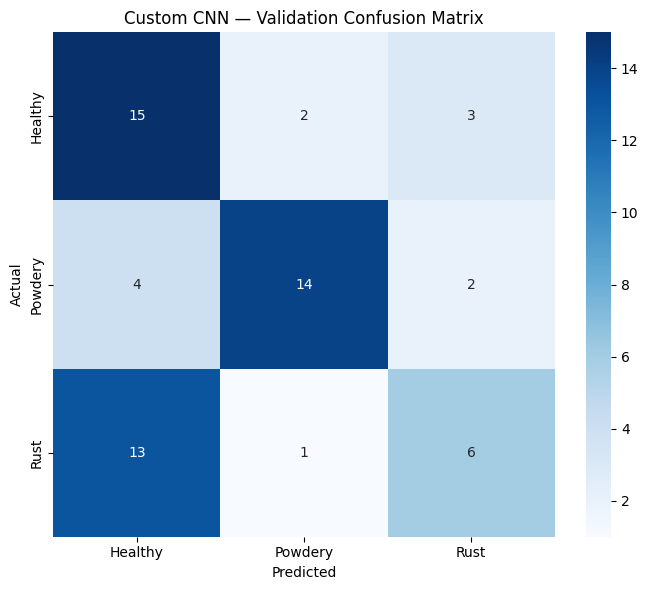

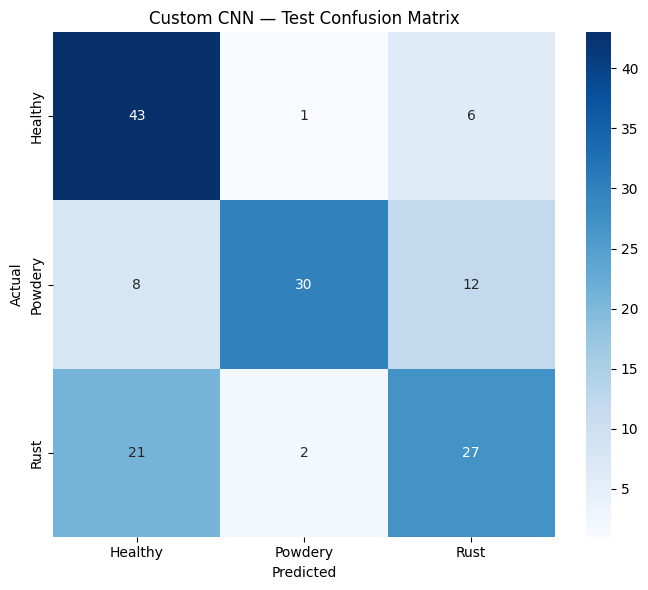

In [ ]:
# ============================================================
# CELL 24 — CONFUSION MATRICES
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 6)
)

cm_val = confusion_matrix(
    y_val_true,
    y_val_pred
)

sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_title("Custom CNN — Validation Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(
    figsize=(7, 6)
)

cm_test = confusion_matrix(
    y_test_true,
    y_test_pred
)

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_title("Custom CNN — Test Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# **Training curves**

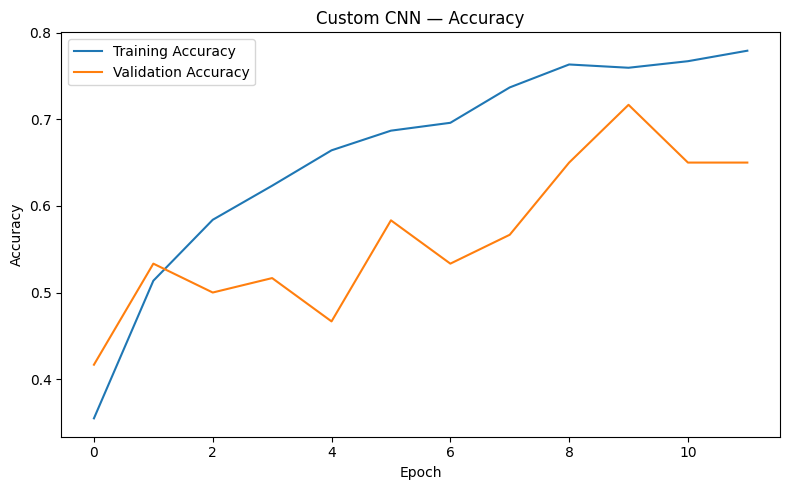

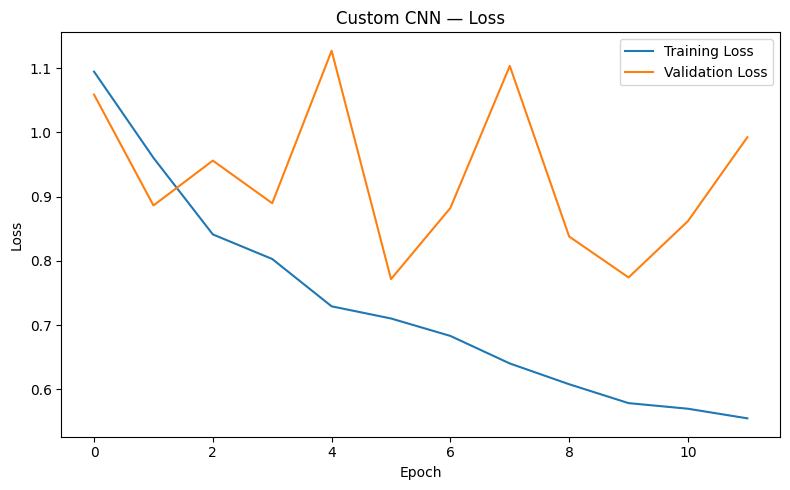

In [ ]:
# ============================================================
# CELL 25 — TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(
    history_cnn.history
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    history_df["accuracy"],
    label="Training Accuracy"
)

ax.plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

ax.set_title("Custom CNN — Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend()

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    history_df["loss"],
    label="Training Loss"
)

ax.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

ax.set_title("Custom CNN — Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()

plt.tight_layout()
plt.show()

# **Compile and train MobileNetV2**

In [ ]:
# ============================================================
# MOBILE NET V2 — BUILD TRANSFER LEARNING MODEL
# ============================================================

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

print("=" * 70)
print("BUILDING MOBILENETV2 TRANSFER LEARNING MODEL")
print("=" * 70)

IMG_SIZE = (224, 224)
NUM_CLASSES = len(CLASS_NAMES)

# Load ImageNet-pretrained MobileNetV2
mobilenet_base = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze pretrained layers
mobilenet_base.trainable = False

# Build classifier
inputs = Input(shape=(224, 224, 3))

x = mobilenet_base(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

mobilenet_model = Model(
    inputs=inputs,
    outputs=outputs,
    name='MobileNetV2_Transfer'
)

mobilenet_model.summary()

print("\nMobileNetV2 model created successfully.")
print("Base model frozen:", not mobilenet_base.trainable)
print("Number of classes:", NUM_CLASSES)

BUILDING MOBILENETV2 TRANSFER LEARNING MODEL
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


MobileNetV2 model created successfully.
Base model frozen: True
Number of classes: 3


In [ ]:
# ============================================================
# CELL 25 — RECREATE DATA GENERATORS
# ============================================================

print("=" * 70)
print("CREATING DATA GENERATORS")
print("=" * 70)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Training augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Validation and test: ONLY normalization
val_test_datagen = ImageDataGenerator(
    rescale=1./255
)

# ------------------------------------------------------------
# Training generator
# ------------------------------------------------------------
train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

# ------------------------------------------------------------
# Validation generator
# ------------------------------------------------------------
val_gen = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASS_NAMES,
    shuffle=False
)

# ------------------------------------------------------------
# Test generator
# ------------------------------------------------------------
test_gen = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASS_NAMES,
    shuffle=False
)

NUM_CLASSES = len(CLASS_NAMES)

print("\n" + "=" * 70)
print("GENERATOR CHECK")
print("=" * 70)

print("Training images:   ", train_gen.samples)
print("Validation images: ", val_gen.samples)
print("Test images:       ", test_gen.samples)

print("Class indices:", train_gen.class_indices)
print("Image shape:  ", train_gen.image_shape)
print("Classes:      ", CLASS_NAMES)

print("=" * 70)

CREATING DATA GENERATORS
Found 1322 images belonging to 3 classes.
Found 60 images belonging to 3 classes.
Found 150 images belonging to 3 classes.

GENERATOR CHECK
Training images:    1322
Validation images:  60
Test images:        150
Class indices: {'Healthy': 0, 'Powdery': 1, 'Rust': 2}
Image shape:   (224, 224, 3)
Classes:       ['Healthy', 'Powdery', 'Rust']


In [ ]:
# ============================================================
# CELL 26 — MOBILENETV2 TRANSFER LEARNING
# ============================================================

print("=" * 70)
print("MOBILENETV2 — TRANSFER LEARNING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Make sure the pretrained base is frozen
# ------------------------------------------------------------
mobilenet_base.trainable = False

# ------------------------------------------------------------
# 2. Compile the model
# ------------------------------------------------------------
mobilenet_model.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ------------------------------------------------------------
# 3. Callbacks
# ------------------------------------------------------------
callbacks_mnv2 = [
    EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        '/content/mobilenetv2_best.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# ------------------------------------------------------------
# 4. Train MobileNetV2
# ------------------------------------------------------------
EPOCHS_MNV2 = 30

start_time = time.time()

history_mnv2 = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_MNV2,
    callbacks=callbacks_mnv2,
    verbose=1
)

mnv2_transfer_time = time.time() - start_time

# ------------------------------------------------------------
# 5. Training summary
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("MOBILENETV2 TRANSFER LEARNING COMPLETE")
print("=" * 70)

print(f"Training time: {mnv2_transfer_time / 60:.2f} minutes")
print(f"Epochs completed: {len(history_mnv2.history['loss'])}")

best_epoch = np.argmax(history_mnv2.history['val_accuracy']) + 1
best_val_acc = max(history_mnv2.history['val_accuracy'])

print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_acc:.4f}")

print("=" * 70)

MOBILENETV2 — TRANSFER LEARNING
Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5522 - loss: 1.0065
Epoch 1: val_accuracy improved from None to 0.95000, saving model to /content/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/mobilenetv2_best.keras
42/42 ━━━━━━━━━━━━━━━━━━━━ 140s 3s/step - accuracy: 0.6899 - loss: 0.7228 - val_accuracy: 0.9500 - val_loss: 0.2591 - learning_rate: 3.0000e-04
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9012 - loss: 0.2920
Epoch 2: val_accuracy did not improve from 0.95000
42/42 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.8979 - loss: 0.2759 - val_accuracy: 0.9500 - val_loss: 0.1760 - learning_rate: 3.0000e-04
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9091 - loss: 0.2411
Epoch 3: val_accuracy did not improve from 0.95000
42/42 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.9213 - loss: 0.2150 - val_accuracy: 0.9500 - val_loss: 0.1373 - learning_rate: 3.0000e-04
Epoch 4/30
42/42 ━━

# **Evaluate MobileNetV2 before fine-tuning**

In [ ]:
# ============================================================
# CELL 27 — INITIAL MOBILENETV2 EVALUATION
# ============================================================

print("=" * 70)
print("MOBILENETV2 — INITIAL EVALUATION")
print("=" * 70)

val_gen.reset()
test_gen.reset()

val_loss_mnv2, val_acc_mnv2 = mobilenet_model.evaluate(
    val_gen,
    verbose=1
)

test_loss_mnv2, test_acc_mnv2 = mobilenet_model.evaluate(
    test_gen,
    verbose=1
)

print("\nValidation loss:     ", round(val_loss_mnv2, 4))
print("Validation accuracy: ", round(val_acc_mnv2, 4))

print("\nTest loss:           ", round(test_loss_mnv2, 4))
print("Test accuracy:       ", round(test_acc_mnv2, 4))

MOBILENETV2 — INITIAL EVALUATION
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9500 - loss: 0.0856
5/5 ━━━━━━━━━━━━━━━━━━━━ 20s 5s/step - accuracy: 0.9733 - loss: 0.1077

Validation loss:      0.0856
Validation accuracy:  0.95

Test loss:            0.1077
Test accuracy:        0.9733


# **MobileNetV2 prediction distribution**

In [ ]:
# ============================================================
# CELL 28 — MOBILENETV2 PREDICTION DISTRIBUTION
# ============================================================

val_gen.reset()
test_gen.reset()

val_probs_mnv2 = mobilenet_model.predict(val_gen, verbose=1)
val_pred_mnv2 = np.argmax(val_probs_mnv2, axis=1)
val_true_mnv2 = val_gen.classes

test_probs_mnv2 = mobilenet_model.predict(test_gen, verbose=1)
test_pred_mnv2 = np.argmax(test_probs_mnv2, axis=1)
test_true_mnv2 = test_gen.classes

print("\n" + "=" * 70)
print("MOBILENETV2 — VALIDATION PREDICTION DISTRIBUTION")
print("=" * 70)

val_pred_counts = np.bincount(
    val_pred_mnv2,
    minlength=NUM_CLASSES
)

val_actual_counts = np.bincount(
    val_true_mnv2,
    minlength=NUM_CLASSES
)

for i, cls in enumerate(CLASS_NAMES):
    print(
        f"{i} - {cls}: "
        f"Predicted={val_pred_counts[i]}, "
        f"Actual={val_actual_counts[i]}"
    )

print("\n" + "=" * 70)
print("MOBILENETV2 — TEST PREDICTION DISTRIBUTION")
print("=" * 70)

test_pred_counts = np.bincount(
    test_pred_mnv2,
    minlength=NUM_CLASSES
)

test_actual_counts = np.bincount(
    test_true_mnv2,
    minlength=NUM_CLASSES
)

for i, cls in enumerate(CLASS_NAMES):
    print(
        f"{i} - {cls}: "
        f"Predicted={test_pred_counts[i]}, "
        f"Actual={test_actual_counts[i]}"
    )

2/2 ━━━━━━━━━━━━━━━━━━━━ 14s 7s/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step

MOBILENETV2 — VALIDATION PREDICTION DISTRIBUTION
0 - Healthy: Predicted=21, Actual=20
1 - Powdery: Predicted=19, Actual=20
2 - Rust: Predicted=20, Actual=20

MOBILENETV2 — TEST PREDICTION DISTRIBUTION
0 - Healthy: Predicted=54, Actual=50
1 - Powdery: Predicted=46, Actual=50
2 - Rust: Predicted=50, Actual=50


# **MobileNetV2 classification reports**

In [ ]:
# ============================================================
# CELL 29 — MOBILENETV2 CLASSIFICATION REPORTS
# ============================================================

print("=" * 70)
print("MOBILENETV2 — VALIDATION CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        val_true_mnv2,
        val_pred_mnv2,
        target_names=CLASS_NAMES,
        digits=4
    )
)

print("=" * 70)
print("MOBILENETV2 — TEST CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        test_true_mnv2,
        test_pred_mnv2,
        target_names=CLASS_NAMES,
        digits=4
    )
)

MOBILENETV2 — VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy     0.9048    0.9500    0.9268        20
     Powdery     1.0000    0.9500    0.9744        20
        Rust     0.9500    0.9500    0.9500        20

    accuracy                         0.9500        60
   macro avg     0.9516    0.9500    0.9504        60
weighted avg     0.9516    0.9500    0.9504        60

MOBILENETV2 — TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy     0.9259    1.0000    0.9615        50
     Powdery     1.0000    0.9200    0.9583        50
        Rust     1.0000    1.0000    1.0000        50

    accuracy                         0.9733       150
   macro avg     0.9753    0.9733    0.9733       150
weighted avg     0.9753    0.9733    0.9733       150



# **MobileNetV2 confusion matrices**

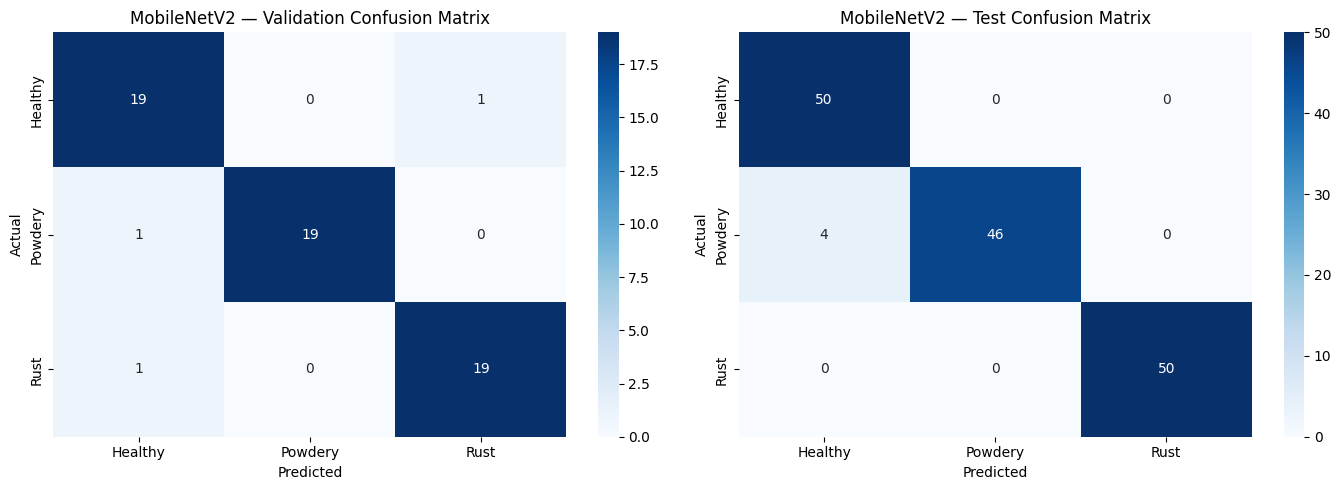

In [ ]:
# ============================================================
# CELL 30 — MOBILENETV2 CONFUSION MATRICES
# ============================================================

cm_val_mnv2 = confusion_matrix(
    val_true_mnv2,
    val_pred_mnv2
)

cm_test_mnv2 = confusion_matrix(
    test_true_mnv2,
    test_pred_mnv2
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_val_mnv2,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("MobileNetV2 — Validation Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_test_mnv2,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("MobileNetV2 — Test Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# **MobileNetV2 training curves**

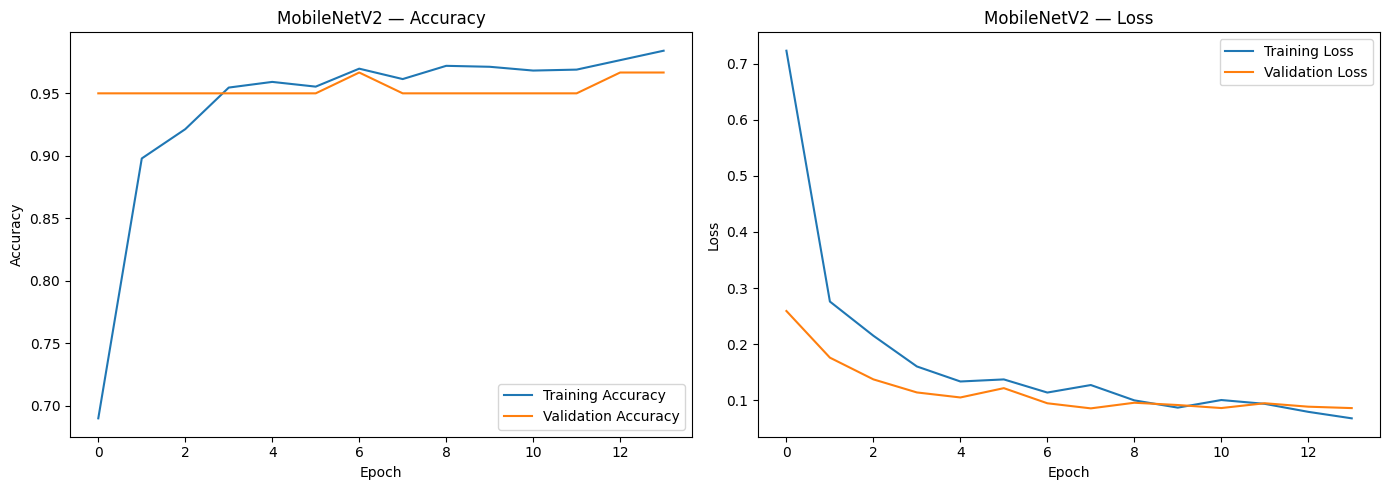

In [ ]:
# ============================================================
# CELL 31 — MOBILENETV2 TRAINING CURVES
# ============================================================

history = history_mnv2.history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    history['accuracy'],
    label='Training Accuracy'
)

axes[0].plot(
    history['val_accuracy'],
    label='Validation Accuracy'
)

axes[0].set_title('MobileNetV2 — Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Loss
axes[1].plot(
    history['loss'],
    label='Training Loss'
)

axes[1].plot(
    history['val_loss'],
    label='Validation Loss'
)

axes[1].set_title('MobileNetV2 — Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

# **Fine-tune MobileNetV2**

In [ ]:
# ============================================================
# CELL 32 — MOBILENETV2 FINE-TUNING
# ============================================================

print("=" * 70)
print("MOBILENETV2 — FINE-TUNING")
print("=" * 70)

# Unfreeze the base model
mobilenet_base.trainable = True

# Freeze all but the final 20 layers
for layer in mobilenet_base.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in mobilenet_base.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

trainable_count = sum(
    1 for layer in mobilenet_model.layers
    if layer.trainable
)

print(f"Trainable top-level layers: {trainable_count}")

mobilenet_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_mnv2_ft = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        mode='max',
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        '/content/mobilenetv2_finetuned_best.keras',
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    )
]

train_gen.reset()
val_gen.reset()

start_time = time.time()

history_mnv2_ft = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    callbacks=callbacks_mnv2_ft,
    verbose=1
)

mnv2_ft_time = time.time() - start_time

print("\n" + "=" * 70)
print(
    f"MobileNetV2 fine-tuning time: "
    f"{mnv2_ft_time / 60:.2f} minutes"
)
print(
    f"Fine-tuning epochs completed: "
    f"{len(history_mnv2_ft.history['loss'])}"
)
print("=" * 70)

MOBILENETV2 — FINE-TUNING
Trainable top-level layers: 6
Epoch 1/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9633 - loss: 0.1199
Epoch 1: val_accuracy improved from None to 0.95000, saving model to /content/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to /content/mobilenetv2_finetuned_best.keras
42/42 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.9637 - loss: 0.1126 - val_accuracy: 0.9500 - val_loss: 0.0947 - learning_rate: 1.0000e-05
Epoch 2/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9755 - loss: 0.0676
Epoch 2: val_accuracy improved from 0.95000 to 0.96667, saving model to /content/mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to /content/mobilenetv2_finetuned_best.keras
42/42 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.9781 - loss: 0.0642 - val_accuracy: 0.9667 - val_loss: 0.0695 - learning_rate: 1.0000e-05
Epoch 3/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9773 - loss: 0.0782
Epoch 3: val_accuracy did not

# **Final MobileNetV2 evaluation**

In [ ]:
# ============================================================
# CELL 33 — FINAL MOBILENETV2 EVALUATION
# ============================================================

print("=" * 70)
print("FINAL MOBILENETV2 EVALUATION")
print("=" * 70)

val_gen.reset()
test_gen.reset()

final_val_loss, final_val_acc = mobilenet_model.evaluate(
    val_gen,
    verbose=1
)

final_test_loss, final_test_acc = mobilenet_model.evaluate(
    test_gen,
    verbose=1
)

print("\nFinal validation loss:     ", round(final_val_loss, 4))
print("Final validation accuracy: ", round(final_val_acc, 4))

print("\nFinal test loss:           ", round(final_test_loss, 4))
print("Final test accuracy:       ", round(final_test_acc, 4))

FINAL MOBILENETV2 EVALUATION
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.9833 - loss: 0.0526
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.9800 - loss: 0.1045

Final validation loss:      0.0526
Final validation accuracy:  0.9833

Final test loss:            0.1045
Final test accuracy:        0.98


**Final MobileNetV2 classification report**

In [ ]:
# ============================================================
# CELL 34 — FINAL MOBILENETV2 CLASSIFICATION REPORT
# ============================================================

val_gen.reset()
test_gen.reset()

final_val_probs = mobilenet_model.predict(
    val_gen,
    verbose=1
)

final_val_pred = np.argmax(
    final_val_probs,
    axis=1
)

final_val_true = val_gen.classes

final_test_probs = mobilenet_model.predict(
    test_gen,
    verbose=1
)

final_test_pred = np.argmax(
    final_test_probs,
    axis=1
)

final_test_true = test_gen.classes

print("=" * 70)
print("FINAL MOBILENETV2 — VALIDATION")
print("=" * 70)

print(
    classification_report(
        final_val_true,
        final_val_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

print("=" * 70)
print("FINAL MOBILENETV2 — TEST")
print("=" * 70)

print(
    classification_report(
        final_test_true,
        final_test_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

1/2 ━━━━━━━━━━━━━━━━━━━━ 7s 8s/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 14s 7s/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step
FINAL MOBILENETV2 — VALIDATION
              precision    recall  f1-score   support

     Healthy     1.0000    0.9500    0.9744        20
     Powdery     1.0000    1.0000    1.0000        20
        Rust     0.9524    1.0000    0.9756        20

    accuracy                         0.9833        60
   macro avg     0.9841    0.9833    0.9833        60
weighted avg     0.9841    0.9833    0.9833        60

FINAL MOBILENETV2 — TEST
              precision    recall  f1-score   support

     Healthy     0.9434    1.0000    0.9709        50
     Powdery     1.0000    0.9400    0.9691        50
        Rust     1.0000    1.0000    1.0000        50

    accuracy                         0.9800       150
   macro avg     0.9811    0.9800    0.9800       150
weighted avg     0.9811    0.9800    0.9800       150



# **Final confusion matrix**

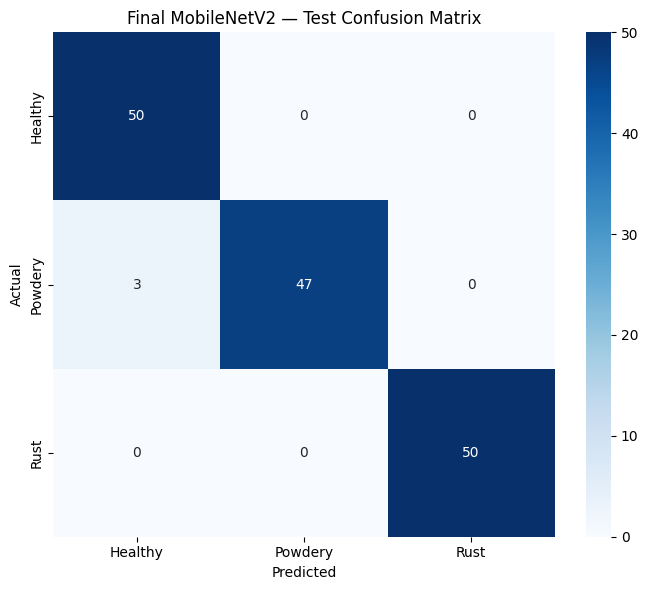

In [ ]:
# ============================================================
# CELL 35 — FINAL MOBILENETV2 CONFUSION MATRIX
# ============================================================

final_cm_test = confusion_matrix(
    final_test_true,
    final_test_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    final_cm_test,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Final MobileNetV2 — Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# **FINAL CELL — CUSTOM CNN vs MOBILENETV2 COMPARISON**

FINAL PERFORMANCE COMPARISON
CUSTOM CNN — EPOCH 6 vs MobileNetV2

Evaluating MobileNetV2...
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9833 - loss: 0.0526
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9800 - loss: 0.1045
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step

PERFORMANCE COMPARISON


,Model,Validation Loss,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Test Loss,Test Accuracy,Test Precision,Test Recall,Test F1
0,Custom CNN — Epoch 6,0.7714,0.5833,0.6126,0.5833,0.5736,0.7887,0.6667,0.7021,0.6667,0.6654
1,MobileNetV2,0.0526,0.9833,0.9841,0.9833,0.9833,0.1045,0.9800,0.9811,0.9800,0.9800



MOBILENETV2 IMPROVEMENT OVER CNN EPOCH 6
Validation Accuracy : CNN = 0.5833 | MobileNetV2 = 0.9833 | Difference = +0.4000
Validation F1       : CNN = 0.5736 | MobileNetV2 = 0.9833 | Difference = +0.4097
Test Accuracy       : CNN = 0.6667 | MobileNetV2 = 0.9800 | Difference = +0.3133
Test F1             : CNN = 0.6654 | MobileNetV2 = 0.9800 | Difference = +0.3146

CONCLUSION
MobileNetV2 performs better than the Custom CNN on the test set by 31.33 percentage points.

CNN values used:
  Validation Accuracy: 0.5833
  Test Accuracy:       0.6667

MobileNetV2 values measured:
  Validation Accuracy: 0.9833
  Test Accuracy:       0.98

Comparison completed.


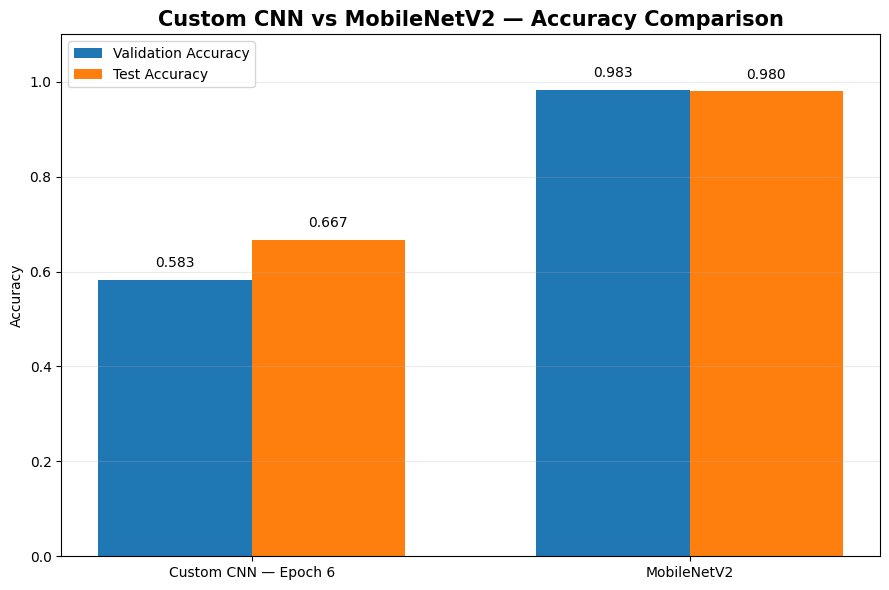

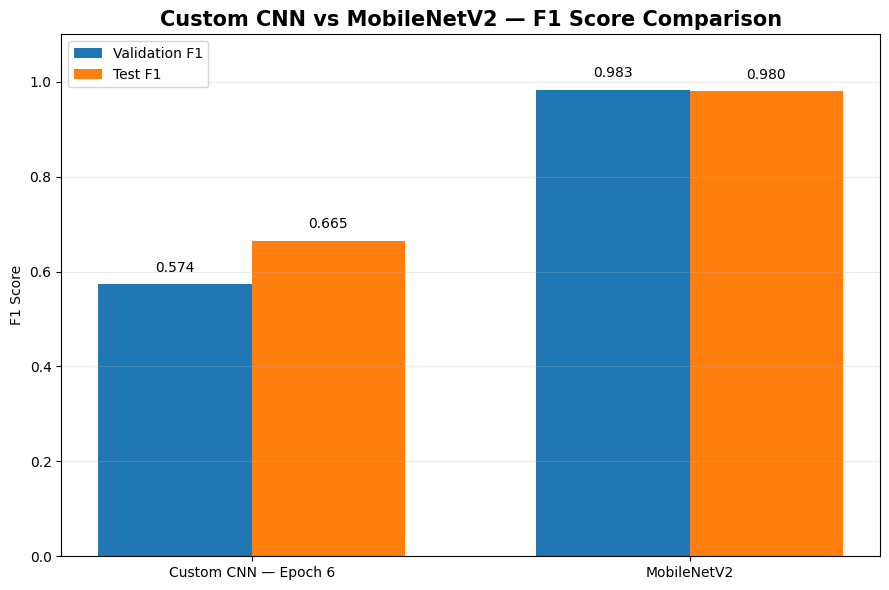

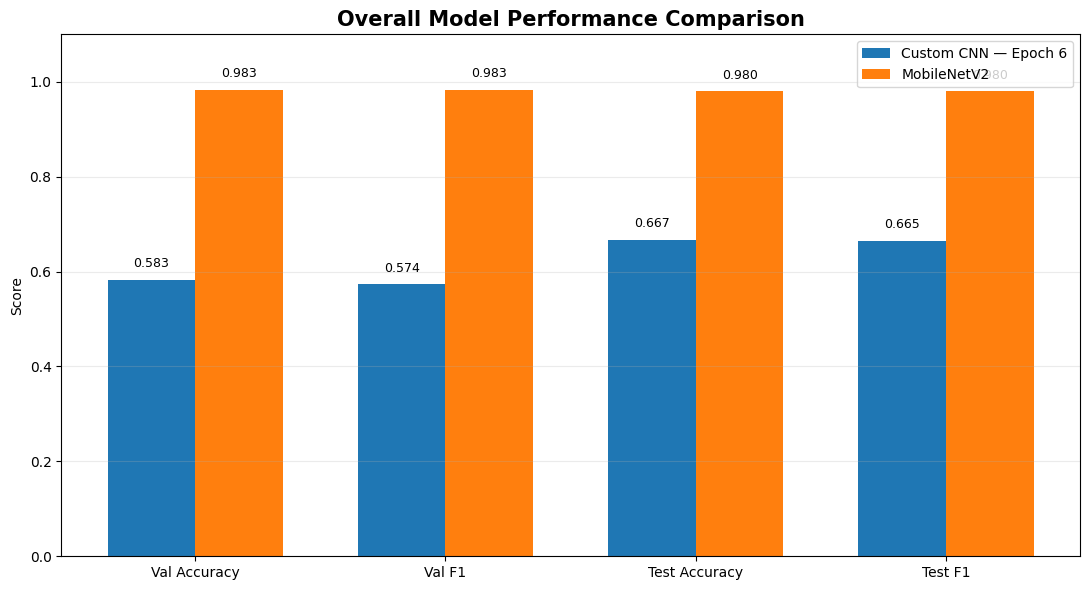


Performance comparison graphs generated successfully.
Saved to: /content/model_performance_comparison.png


In [ ]:
# ================================================================
# FINAL COMPARISON
# CNN EPOCH 6 vs MOBILENETV2
# Uses the ACTUAL CNN RESULTS already obtained
# ================================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("FINAL PERFORMANCE COMPARISON")
print("CUSTOM CNN — EPOCH 6 vs MobileNetV2")
print("=" * 70)


# ================================================================
# CNN RESULTS — FROM YOUR ACTUAL EVALUATION
# ================================================================

cnn_val_loss = 0.7714
cnn_val_accuracy = 0.5833

cnn_test_loss = 0.7887
cnn_test_accuracy = 0.6667

cnn_val_precision = 0.6126
cnn_val_recall = 0.5833
cnn_val_f1 = 0.5736

cnn_test_precision = 0.7021
cnn_test_recall = 0.6667
cnn_test_f1 = 0.6654


# ================================================================
# MOBILENETV2 — EVALUATE CURRENT TRAINED MODEL
# ================================================================

print("\nEvaluating MobileNetV2...")

val_gen.reset()

mnv2_val_loss, mnv2_val_accuracy = mobilenet_model.evaluate(
    val_gen,
    verbose=1
)

val_gen.reset()

mnv2_val_probs = mobilenet_model.predict(
    val_gen,
    verbose=1
)

mnv2_val_pred = np.argmax(mnv2_val_probs, axis=1)
mnv2_val_true = val_gen.classes


test_gen.reset()

mnv2_test_loss, mnv2_test_accuracy = mobilenet_model.evaluate(
    test_gen,
    verbose=1
)

test_gen.reset()

mnv2_test_probs = mobilenet_model.predict(
    test_gen,
    verbose=1
)

mnv2_test_pred = np.argmax(mnv2_test_probs, axis=1)
mnv2_test_true = test_gen.classes


# ================================================================
# MOBILENETV2 PRECISION / RECALL / F1
# ================================================================

from sklearn.metrics import precision_recall_fscore_support

(
    mnv2_val_precision,
    mnv2_val_recall,
    mnv2_val_f1,
    _
) = precision_recall_fscore_support(
    mnv2_val_true,
    mnv2_val_pred,
    average="weighted",
    zero_division=0
)

(
    mnv2_test_precision,
    mnv2_test_recall,
    mnv2_test_f1,
    _
) = precision_recall_fscore_support(
    mnv2_test_true,
    mnv2_test_pred,
    average="weighted",
    zero_division=0
)


# ================================================================
# BUILD FINAL TABLE
# ================================================================

comparison = pd.DataFrame({

    "Model": [
        "Custom CNN — Epoch 6",
        "MobileNetV2"
    ],

    "Validation Loss": [
        cnn_val_loss,
        mnv2_val_loss
    ],

    "Validation Accuracy": [
        cnn_val_accuracy,
        mnv2_val_accuracy
    ],

    "Validation Precision": [
        cnn_val_precision,
        mnv2_val_precision
    ],

    "Validation Recall": [
        cnn_val_recall,
        mnv2_val_recall
    ],

    "Validation F1": [
        cnn_val_f1,
        mnv2_val_f1
    ],

    "Test Loss": [
        cnn_test_loss,
        mnv2_test_loss
    ],

    "Test Accuracy": [
        cnn_test_accuracy,
        mnv2_test_accuracy
    ],

    "Test Precision": [
        cnn_test_precision,
        mnv2_test_precision
    ],

    "Test Recall": [
        cnn_test_recall,
        mnv2_test_recall
    ],

    "Test F1": [
        cnn_test_f1,
        mnv2_test_f1
    ]
})


# ================================================================
# DISPLAY
# ================================================================

print("\n" + "=" * 70)
print("PERFORMANCE COMPARISON")
print("=" * 70)

display(
    comparison.style.format({
        "Validation Loss": "{:.4f}",
        "Validation Accuracy": "{:.4f}",
        "Validation Precision": "{:.4f}",
        "Validation Recall": "{:.4f}",
        "Validation F1": "{:.4f}",
        "Test Loss": "{:.4f}",
        "Test Accuracy": "{:.4f}",
        "Test Precision": "{:.4f}",
        "Test Recall": "{:.4f}",
        "Test F1": "{:.4f}"
    })
)


# ================================================================
# IMPROVEMENT
# ================================================================

print("\n" + "=" * 70)
print("MOBILENETV2 IMPROVEMENT OVER CNN EPOCH 6")
print("=" * 70)

print(
    f"Validation Accuracy : "
    f"CNN = {cnn_val_accuracy:.4f} | "
    f"MobileNetV2 = {mnv2_val_accuracy:.4f} | "
    f"Difference = {mnv2_val_accuracy - cnn_val_accuracy:+.4f}"
)

print(
    f"Validation F1       : "
    f"CNN = {cnn_val_f1:.4f} | "
    f"MobileNetV2 = {mnv2_val_f1:.4f} | "
    f"Difference = {mnv2_val_f1 - cnn_val_f1:+.4f}"
)

print(
    f"Test Accuracy       : "
    f"CNN = {cnn_test_accuracy:.4f} | "
    f"MobileNetV2 = {mnv2_test_accuracy:.4f} | "
    f"Difference = {mnv2_test_accuracy - cnn_test_accuracy:+.4f}"
)

print(
    f"Test F1             : "
    f"CNN = {cnn_test_f1:.4f} | "
    f"MobileNetV2 = {mnv2_test_f1:.4f} | "
    f"Difference = {mnv2_test_f1 - cnn_test_f1:+.4f}"
)


# ================================================================
# FINAL CONCLUSION
# ================================================================

print("\n" + "=" * 70)
print("CONCLUSION")
print("=" * 70)

if mnv2_test_accuracy > cnn_test_accuracy:
    print(
        f"MobileNetV2 performs better than the Custom CNN "
        f"on the test set by "
        f"{(mnv2_test_accuracy - cnn_test_accuracy) * 100:.2f} percentage points."
    )
else:
    print("Custom CNN performs better on the test set.")

print("\nCNN values used:")
print("  Validation Accuracy:", cnn_val_accuracy)
print("  Test Accuracy:      ", cnn_test_accuracy)

print("\nMobileNetV2 values measured:")
print("  Validation Accuracy:", round(mnv2_val_accuracy, 4))
print("  Test Accuracy:      ", round(mnv2_test_accuracy, 4))

print("\nComparison completed.")

# ================================================================
# VISUAL COMPARISON GRAPHS
# ================================================================

import matplotlib.pyplot as plt
import numpy as np

models = comparison["Model"].values

# ------------------------------------------------
# GRAPH 1 — ACCURACY
# ------------------------------------------------

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width/2,
    comparison["Validation Accuracy"],
    width,
    label="Validation Accuracy"
)

bars2 = ax.bar(
    x + width/2,
    comparison["Test Accuracy"],
    width,
    label="Test Accuracy"
)

ax.set_title(
    "Custom CNN vs MobileNetV2 — Accuracy Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.1)

ax.legend()
ax.grid(axis="y", alpha=0.25)

# Add values above bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.02,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.tight_layout()
plt.show()


# ------------------------------------------------
# GRAPH 2 — F1 SCORE
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width/2,
    comparison["Validation F1"],
    width,
    label="Validation F1"
)

bars2 = ax.bar(
    x + width/2,
    comparison["Test F1"],
    width,
    label="Test F1"
)

ax.set_title(
    "Custom CNN vs MobileNetV2 — F1 Score Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("F1 Score")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.1)

ax.legend()
ax.grid(axis="y", alpha=0.25)

# Add values above bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.02,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.tight_layout()
plt.show()


# ------------------------------------------------
# GRAPH 3 — ALL KEY METRICS
# ------------------------------------------------

metrics = [
    "Validation Accuracy",
    "Validation F1",
    "Test Accuracy",
    "Test F1"
]

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(metrics))
width = 0.35

cnn_values = [
    comparison.loc[0, metric]
    for metric in metrics
]

mnv2_values = [
    comparison.loc[1, metric]
    for metric in metrics
]

bars1 = ax.bar(
    x - width/2,
    cnn_values,
    width,
    label="Custom CNN — Epoch 6"
)

bars2 = ax.bar(
    x + width/2,
    mnv2_values,
    width,
    label="MobileNetV2"
)

ax.set_title(
    "Overall Model Performance Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(
    ["Val Accuracy", "Val F1", "Test Accuracy", "Test F1"]
)

ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

# Add values
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.02,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()

# Save final graph
plt.savefig(
    "/content/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPerformance comparison graphs generated successfully.")
print("Saved to: /content/model_performance_comparison.png")